# 05 — Overgrinding: signer work vs. verifier work at fixed size (OQ-3)

Kudinov asked (bitcoindev, 2025-12-09): *"would it be reasonable to choose larger signatures if they offer
lower verification costs?"* WOTS+C has a knob that trades signer work for verifier work **at the same size**:
the target digit sum S. The verifier walks (w−1)·len1 − S chain steps per layer, so raising S saves
verification and costs more grinding. Blockstream's HW-wallet benchmark moves S from 96 to 140 at w = 4.

Per layer, for w = 4 (len1 = 64) and w = 16 (len1 = 32): expected and measured tries, p99, verifier chain
steps, and signer p99 seconds on each class.

In [1]:
import sys; sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import common as C
from runner.configs import EXTRA
OUT = C.out_dir('05_oq3')
runs = sorted(C.RAW.glob('oq3-*'), key=lambda p: p.stat().st_mtime)
RUN = runs[-1].name if runs and (runs[-1] / 'summary.jsonl').exists() else None
print('measured run:', RUN or 'none yet — analytic only (run: python -m runner.run_campaign --extra oq3)')
meas = C.summary(RUN) if RUN else None
# the shortlist's w=16 S=240/304 points from the main run complete the w=16 sweep
main = C.summary()

measured run: none yet — analytic only (run: python -m runner.run_campaign --extra oq3)


In [2]:
rows = []
cfgs = EXTRA['oq3']()
extra_main = [c for c in ('wots-w16-S240-z0', 'wots-w16-S304-z0') if c in main.index]
for c in cfgs + [None] * len(extra_main):
    if c is None:
        cid = extra_main.pop(0); r = main.loc[cid]; w, S, E = int(r.w), int(r.S), r.expected_tries; src = C.RUN_ID
    else:
        cid, w, S, E = c.id, c.w, c.S, c.expected_tries()
        r = meas.loc[cid] if meas is not None and cid in meas.index else None; src = RUN if r is not None else None
    len1 = 128 // (w.bit_length() - 1)
    rows.append({'config_id': cid, 'w': w, 'S': S, 'E_tries': E, 'geo_p99': C.geometric_quantile(E, 0.99),
                 'measured_ratio': r.ratio if r is not None else np.nan,
                 'measured_p99': r.p99 if r is not None else np.nan, 'n': int(r.n) if r is not None else 0,
                 'verify_chain_steps': (w - 1) * len1 - S, 'run': src})
oq = pd.DataFrame(rows).sort_values(['w', 'S']).set_index('config_id')
for w, g in oq.groupby('w'):
    base = g.verify_chain_steps.iloc[0]
    oq.loc[g.index, 'verify_saved_vs_mean_S'] = 1 - g.verify_chain_steps / base
lad = C.ladder()
for cid in ('class0a', 'class0b', 'class2'):
    oq[f"p99_s {lad.loc[cid, 'label']}"] = oq.geo_p99 / lad.loc[cid, 'comp_per_s']
C.to_markdown(oq.round(4), OUT / 'oq3_sweep.md'); oq.to_csv(OUT / 'oq3_sweep.csv')
oq

,w,S,E_tries,geo_p99,measured_ratio,measured_p99,n,verify_chain_steps,run,verify_saved_vs_mean_S,"p99_s HW wallet MCU, software SHA (Cortex-M4)",p99_s HW wallet MCU + SHA peripheral,"p99_s i5-13420H SHA-NI, 12 threads"
config_id,,,,,,,,,,,,,
wots-w4-S96-z0,4,96,2.247970e+01,102.0,NaN,NaN,0,96,NaN,0.000000,0.002550,0.000850,4.380839e-07
wots-w4-S100-z0,4,100,2.481850e+01,112.0,NaN,NaN,0,92,NaN,0.041667,0.002800,0.000933,4.810333e-07
wots-w4-S104-z0,4,104,3.341267e+01,152.0,NaN,NaN,0,88,NaN,0.083333,0.003800,0.001267,6.528310e-07
wots-w4-S108-z0,4,108,5.492153e+01,251.0,NaN,NaN,0,84,NaN,0.125000,0.006275,0.002092,1.078030e-06
wots-w4-S112-z0,4,112,1.104570e+02,507.0,NaN,NaN,0,80,NaN,0.166667,0.012675,0.004225,2.177535e-06
wots-w4-S116-z0,4,116,2.726380e+02,1254.0,NaN,NaN,0,76,NaN,0.208333,0.031350,0.010450,5.385855e-06
wots-w4-S120-z0,4,120,8.292368e+02,3817.0,NaN,NaN,0,72,NaN,0.250000,0.095425,0.031808,1.639379e-05
wots-w4-S124-z0,4,124,3.123956e+03,14385.0,NaN,NaN,0,68,NaN,0.291667,0.359625,0.119875,6.178272e-05
wots-w4-S128-z0,4,128,1.467037e+04,67558.0,NaN,NaN,0,64,NaN,0.333333,1.688950,0.562983,2.901576e-04


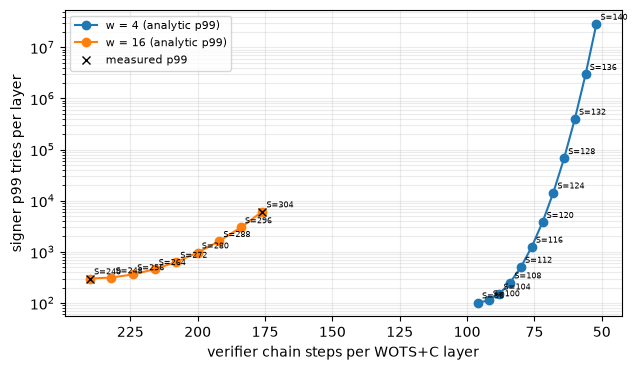

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for w, g in oq.groupby('w'):
    ax.plot(g.verify_chain_steps, g.geo_p99, 'o-', label=f'w = {w} (analytic p99)')
    m = g.dropna(subset=['measured_p99'])
    if len(m): ax.plot(m.verify_chain_steps, m.measured_p99, 'kx', ms=6)
    for _, r in g.iterrows(): ax.annotate(f"S={r.S}", (r.verify_chain_steps, r.geo_p99), fontsize=6, xytext=(3, 3), textcoords='offset points')
ax.plot([], [], 'kx', label='measured p99')
ax.set_yscale('log'); ax.set_xlabel('verifier chain steps per WOTS+C layer'); ax.set_ylabel('signer p99 tries per layer')
ax.invert_xaxis(); ax.grid(alpha=0.25, which='both'); ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(OUT / 'oq3_tradeoff.png', dpi=160)

Reading (left to right = less verifier work): at w = 4, S 96 → 128 cuts per-layer verification by a third
for ≈ 650× more grinding (≈ 1.7 s p99 per layer on a Cortex-M4 at the cited 4·10⁴ comp/s). The last steps
(S ≥ 136) cost orders of magnitude more for little extra saving. Size is identical along each curve.